Expected UAV delay: 53 samples
Expected UAV distance: 800 metres

NO-NOISE TEST
Detected peak: 256.0
Peak delay: 53 samples
Expected delay: 53 samples

Detection threshold: 47.23

Actual UAV present: False
Measured peak: 36.03
Detected delay: 44 samples
UAV detected: False


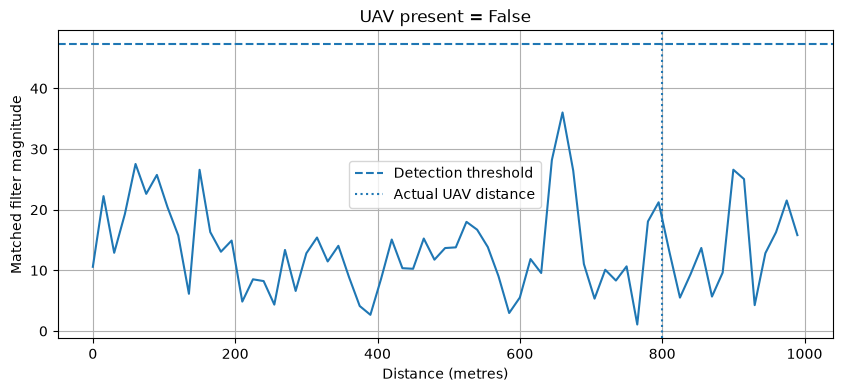


Actual UAV present: True
Measured peak: 819.75
Detected delay: 53 samples
UAV detected: True


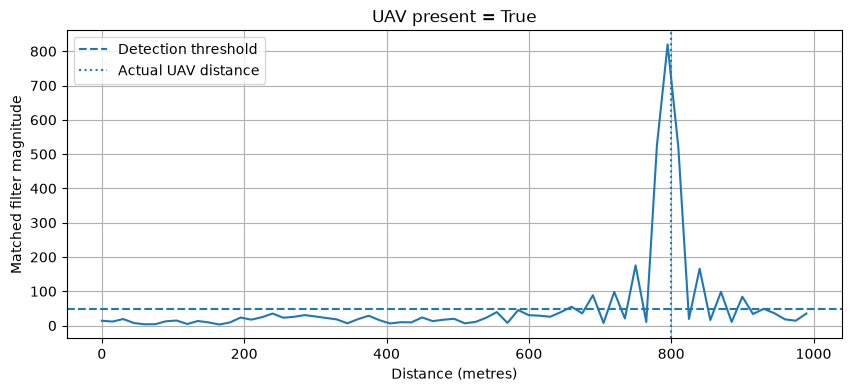

In [10]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate, correlation_lags

# ----------------------------------
# 1. Simulation assumptions
# ----------------------------------
c = 3e8
fs = 10e6
bandwidth = 5e6
N = 256

uav_distance = 800
echo_snr_db = 10

received_length = 1024
delay_samples = round((2 * uav_distance / c) * fs)

rng = np.random.default_rng(42)

# ----------------------------------
# 2. Generate transmitted chirp
# ----------------------------------
t = np.arange(N) / fs
duration = N / fs
chirp_rate = bandwidth / duration

tx = np.exp(1j * np.pi * chirp_rate * t**2)

print("Expected UAV delay:", delay_samples, "samples")
print("Expected UAV distance:", uav_distance, "metres")

# ----------------------------------
# 3. Generate received signal
# ----------------------------------
def generate_signal(uav_present):
    noise = (
        rng.normal(0, 1/np.sqrt(2), received_length)
        + 1j * rng.normal(0, 1/np.sqrt(2), received_length)
    )

    rx = noise.copy()

    if uav_present:
        amplitude = np.sqrt(10**(echo_snr_db / 10))
        rx[delay_samples:delay_samples + N] += amplitude * tx

    return rx

# ----------------------------------
# 4. Matched filter
# ----------------------------------
def get_peak(rx):
    result = correlate(rx, tx, mode="full", method="fft")
    lags = correlation_lags(len(rx), len(tx), mode="full")

    max_delay = int((2 * 1000 / c) * fs)

    valid = (lags >= 0) & (lags <= max_delay)

    peak_index = np.argmax(np.abs(result[valid]))
    peak_value = np.abs(result[valid])[peak_index]
    peak_lag = lags[valid][peak_index]

    return peak_value, peak_lag, result, lags

# ----------------------------------
# 5. First test: UAV without noise
# ----------------------------------
rx_clean = np.zeros(received_length, dtype=complex)
rx_clean[delay_samples:delay_samples + N] = tx

clean_peak, clean_lag, _, _ = get_peak(rx_clean)

print("\nNO-NOISE TEST")
print("Detected peak:", round(clean_peak, 2))
print("Peak delay:", clean_lag, "samples")
print("Expected delay:", delay_samples, "samples")

# ----------------------------------
# 6. Calibrate threshold using noise
# ----------------------------------
noise_peaks = []

for _ in range(2000):
    rx_noise = generate_signal(False)
    peak, _, _, _ = get_peak(rx_noise)
    noise_peaks.append(peak)

threshold = np.quantile(noise_peaks, 0.99)

print("\nDetection threshold:", round(threshold, 2))

# ----------------------------------
# 7. Test UAV absent and present
# ----------------------------------
for present in [False, True]:

    rx = generate_signal(present)
    peak, lag, result, lags = get_peak(rx)

    detected = peak > threshold

    print("\nActual UAV present:", present)
    print("Measured peak:", round(peak, 2))
    print("Detected delay:", lag, "samples")
    print("UAV detected:", detected)

    # Plot matched-filter output
    valid = (lags >= 0) & (lags <= int((2 * 1000 / c) * fs))
    ranges = lags[valid] * c / (2 * fs)

    plt.figure(figsize=(10, 4))
    plt.plot(ranges, np.abs(result[valid]))
    plt.axhline(threshold, linestyle="--", label="Detection threshold")
    plt.axvline(uav_distance, linestyle=":", label="Actual UAV distance")
    plt.xlabel("Distance (metres)")
    plt.ylabel("Matched filter magnitude")
    plt.title(f"UAV present = {present}")
    plt.legend()
    plt.grid(True)
    plt.show()


DISTANCE-WISE UAV DETECTION RESULTS


,Actual Distance (m),Delay (samples),Estimated Distance (m),Matched Filter Peak,Detected
0,100,7,105.0,805.60,True
1,200,13,195.0,789.36,True
2,400,27,405.0,819.81,True
3,600,40,600.0,812.11,True
4,800,53,795.0,807.84,True
5,950,63,945.0,805.70,True


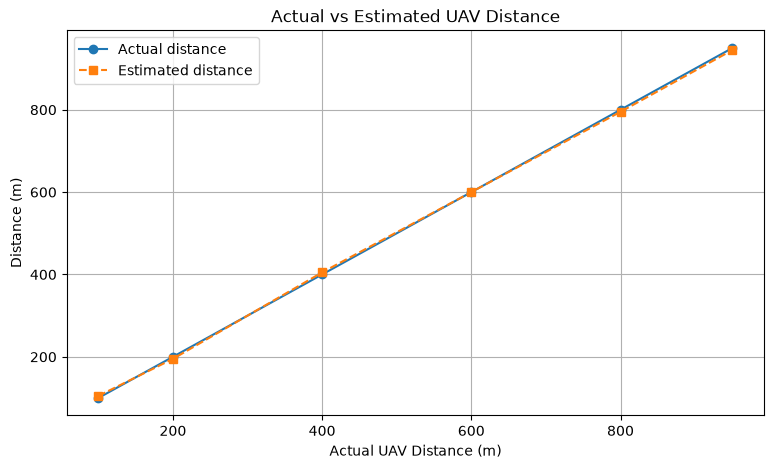

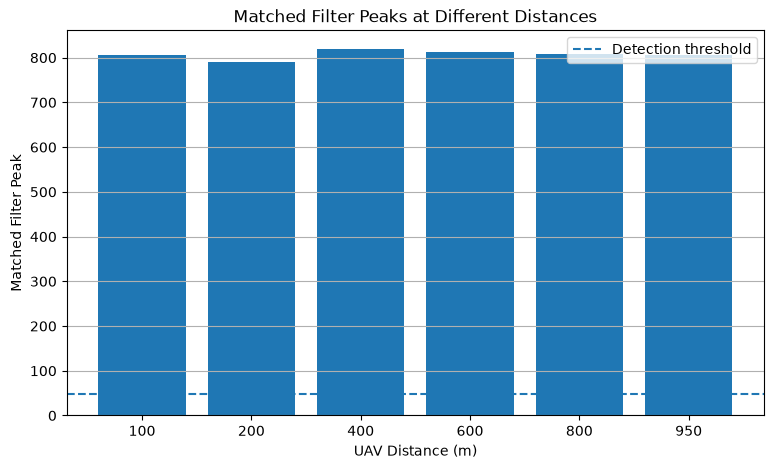

In [11]:

# ==========================================
# DISTANCE-WISE UAV DETECTION
# ==========================================

distances = [100, 200, 400, 600, 800, 950]

results = []

for distance in distances:

    # Calculate round-trip delay
    delay = round((2 * distance / c) * fs)

    # Generate noise
    noise = (
        rng.normal(0, 1/np.sqrt(2), received_length)
        + 1j * rng.normal(0, 1/np.sqrt(2), received_length)
    )

    # Create received signal
    rx = noise.copy()

    # Add UAV echo at the calculated delay
    amplitude = np.sqrt(10**(echo_snr_db / 10))

    rx[delay:delay + N] += amplitude * tx

    # Apply matched filter
    peak, detected_delay, matched_output, lags = get_peak(rx)

    # Estimate UAV distance
    estimated_distance = detected_delay * c / (2 * fs)

    # Make detection decision
    detected = peak > threshold

    results.append({
        "Actual Distance (m)": distance,
        "Delay (samples)": delay,
        "Estimated Distance (m)": round(estimated_distance, 2),
        "Matched Filter Peak": round(peak, 2),
        "Detected": detected
    })


# ==========================================
# DISPLAY RESULTS
# ==========================================

import pandas as pd

df = pd.DataFrame(results)

print("DISTANCE-WISE UAV DETECTION RESULTS")
display(df)


# ==========================================
# PLOT ACTUAL VS ESTIMATED DISTANCE
# ==========================================

plt.figure(figsize=(9, 5))

plt.plot(
    df["Actual Distance (m)"],
    df["Actual Distance (m)"],
    marker="o",
    label="Actual distance"
)

plt.plot(
    df["Actual Distance (m)"],
    df["Estimated Distance (m)"],
    marker="s",
    linestyle="--",
    label="Estimated distance"
)

plt.xlabel("Actual UAV Distance (m)")
plt.ylabel("Distance (m)")
plt.title("Actual vs Estimated UAV Distance")
plt.legend()
plt.grid(True)
plt.show()


# ==========================================
# PLOT MATCHED FILTER PEAKS
# ==========================================

plt.figure(figsize=(9, 5))

plt.bar(
    df["Actual Distance (m)"].astype(str),
    df["Matched Filter Peak"]
)

plt.axhline(
    threshold,
    linestyle="--",
    label="Detection threshold"
)

plt.xlabel("UAV Distance (m)")
plt.ylabel("Matched Filter Peak")
plt.title("Matched Filter Peaks at Different Distances")
plt.legend()
plt.grid(axis="y")
plt.show()
